In [1]:
import uproot
import pandas
import numpy as np
import os

import ipympl

from scipy import interpolate
import scipy

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mplColors

uproot.__version__

'5.0.8'

In [2]:
class StyleThing:
  def __init__(self, color, linestyle):
    self.col = color
    self.ls = linestyle
    
class MyStyleSet:
  def __init__(self, option = "nobles"):
    
    # medium types. these are what populate the other arrays 
    self.air = StyleThing('goldenrod', '-')
    
    self.lxe = StyleThing('darkviolet', '-')
    self.lxe2 = StyleThing('fuchsia', '-')

    self.cf4 = StyleThing('deepskyblue', '-')
    # self.cf4_2 = StyleThing('deepskyblue', '-')
    
    self.green = StyleThing('springgreen', '-')
    
    self.red = StyleThing('red', '-')
    
    self.test = StyleThing('#d94ff5', '-')
    
    # line styles
    self.line1 = "-"
    self.line2 = "--"
    self.line3 = "-."
    
    # all colors
    self.names = [x for x in self.__dict__.keys() if isinstance(self.__dict__[x], StyleThing)]
    self.allColsStr = [x.col for x in self.__dict__.values() if isinstance(x, StyleThing)]
    self.allColsObj = mplColors.to_rgba_array(self.allColsStr).reshape(1, -1, 4)
    
  def show(self):
    fig, ax = plt.subplots(figsize = (len(self.names)*1.5, 2))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(self.allColsObj, aspect=0.5)
    for i, (color, name) in enumerate(zip(self.allColsStr, self.names)):
      txt = f"{name} \n {color}"
      ax.text(i, 0, txt, ha='center', va='center')
    plt.show()
    return

ms = MyStyleSet()
    
    

['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']


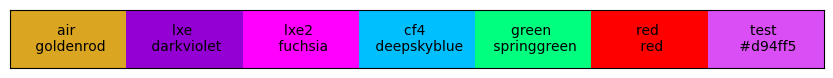

In [3]:
# show it off
ms.lxe.col
print(ms.names)

ms.show()

In [4]:
# # Define your custom style
# plt.rcParams['axes.titlesize'] = 20
# plt.rcParams['axes.labelsize'] = 14
# plt.rcParams['lines.linewidth'] = 2
# plt.rcParams['lines.markersize'] = 10
# plt.rcParams['xtick.labelsize'] = 12
# plt.rcParams['ytick.labelsize'] = 12

# Define your custom colors
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[ms.air.col, ms.lxe.col, ms.cf4.col, ms.green.col, ms.red.col, ms.test.col])

# plt.rcParams.keys()

# my_color = Style(color='r', linestyle='-')
# type(my_color)


In [5]:
## loading the data ##
rootPath1 = "../outputs_v1_noImaginary/"
rootPath2 = "../outputs_v2_allPhysics/"
rootPath3 = "../outputs_v3_amorphous/"

opticsPath_g4 = "../g4PDEsim/dataOptics/"
scintPath_g4 = "../g4PDEsim/data_cf4_scint/"

In [6]:
## Only load the air data
fnames = []
fnames.append("bulk amorphous") # A
fA = uproot.open(os.path.join(rootPath3, "bulk_air_N1e5_110-1050nm_0-85deg.root"))

fnames.append("passivation amorphous") # B
fB = uproot.open(os.path.join(rootPath3, "surface_air_N1e5_110-1050nm_0-85deg.root"))

fnames.append("bulk crystalline") # C
fC = uproot.open(os.path.join(rootPath2, "noQuartz_air_N1e5_120-1050nm_0-85deg.root"))

fnames.append("passivation crystalline") # D
fD = uproot.open(os.path.join(rootPath2, "noWindow_air_N1e5_120-1050nm_0-85deg.root"))
files = [fA, fB, fC, fD]

## getting trees
ttlist = [f["simOutput"] for f in files]

dflist = [ tt.arrays(library="pd").drop_duplicates() for tt in ttlist ]
for df, name in zip(dflist, fnames):
  df["eff"] = df["fNinBulk"]/df["fNphoton"]
  df["ref"] = 1-df["eff"]
  df.loc[:, "dfName"] = name

dfA = dflist[0]
dfB = dflist[1]
dfC = dflist[2]
dfD = dflist[3]

angles = dfA['fAngle'].unique()
print(angles)

column_names = ["fNphoton", "fPhotonWln", "fAngle", "fNonWindow", "fNonSurface", "fNonBulk", "fNinBulk"]

dfC.head(5)

[ 0.          5.00000214 10.00000429 14.99997778 20.00000857 24.99998207
 30.00001286 34.99998635 40.00001714 44.99999064 50.00002143 54.99999492
 60.00014031 64.99977003 69.9999727  75.00017538 79.9998051  85.00000778]


,fNphoton,fPhotonWln,fAngle,fNonWindow,fNonSurface,fNonBulk,fNinBulk,eff,ref,dfName
0,100000,120.023425,0.000000,0,0,45775,54225,0.54225,0.45775,bulk crystalline
1,100000,120.023425,19.400007,0,0,45861,54139,0.54139,0.45861,bulk crystalline
2,100000,120.023425,27.600007,0,0,46716,53284,0.53284,0.46716,bulk crystalline
3,100000,120.023425,34.000003,0,0,47377,52623,0.52623,0.47377,bulk crystalline
4,100000,120.023425,39.499997,0,0,48565,51435,0.51435,0.48565,bulk crystalline


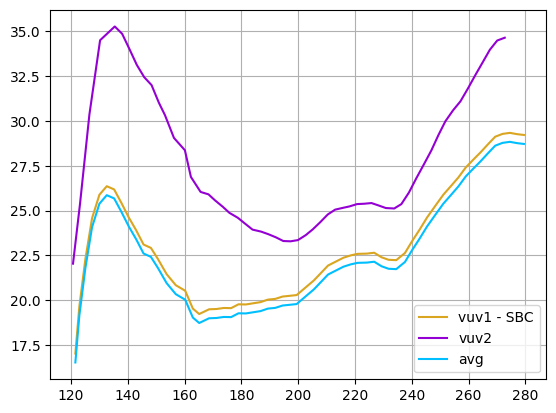

In [7]:
from scipy import interpolate

pdeX, pdeY = np.loadtxt(os.path.join(opticsPath_g4, "SiPMeff_Ham_5V.dat"), unpack=True, skiprows=1, delimiter = "\t")
pdeY *= 1./100

reg_dataPath = "../data_allOptics/"
rvuv = np.loadtxt(os.path.join(reg_dataPath, "vuv_Ref_air_nexo.csv"), skiprows=1, delimiter = ",")
column = rvuv[:, 1]

# Interpolate columns 1 and 2
f_interp1 = interpolate.interp1d(rvuv[:, 0], rvuv[:, 1])

# Interpolate columns 3 and 4
f_interp2 = interpolate.interp1d(rvuv[:, 2], rvuv[:, 3])

# Average the interpolated values
vuvR_x = rvuv[:, 0]
vuvR_x = np.sort(vuvR_x)
vuvR_y = f_interp1(vuvR_x) # only look at first SiPM



plt.plot(rvuv[:, 0], rvuv[:, 1], label = "vuv1 - SBC")
plt.plot(rvuv[:, 2], rvuv[:, 3], label = "vuv2")
plt.plot(vuvR_x, vuvR_y-0.5, label = "avg")
plt.legend()
plt.grid()

vuvR_y = vuvR_y/100 if max(vuvR_y) > 1 else vuvR_y

[ 0.          5.00000214 10.00000429 14.99997778 20.00000857 24.99998207
 30.00001286 34.99998635 40.00001714 44.99999064 50.00002143 54.99999492
 60.00014031 64.99977003 69.9999727  75.00017538 79.9998051  85.00000778]


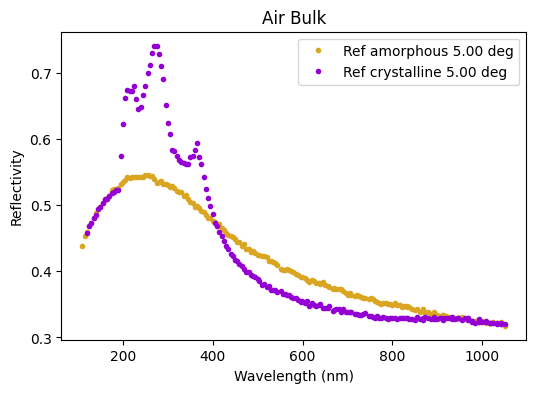

In [8]:
%matplotlib widget
%matplotlib inline

anglesC = dfC['fAngle'].unique()

dfA_specific = dfA[dfA["fAngle"] == angles[1]]
dfC_specific = dfC[dfC["fAngle"] == anglesC[1]]

thisName = dfA_specific["dfName"].values[0]
print(angles)

fig, (ax) = plt.subplots(1, 1, figsize=(6, 4))
dfA_specific.plot(x='fPhotonWln', y='ref', marker=".", linestyle="None", ax = ax, label=f"Ref amorphous {angles[1]:0.2f} deg")
dfC_specific.plot(x='fPhotonWln', y='ref', marker=".", linestyle="None", ax = ax, label=f"Ref crystalline {angles[1]:0.2f} deg")

plt.title("Air Bulk")
plt.xlabel('Wavelength (nm)')
plt.ylabel('Reflectivity')
plt.show()
# plt.close('all')
print()


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_51174/3423547935.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('inferno')


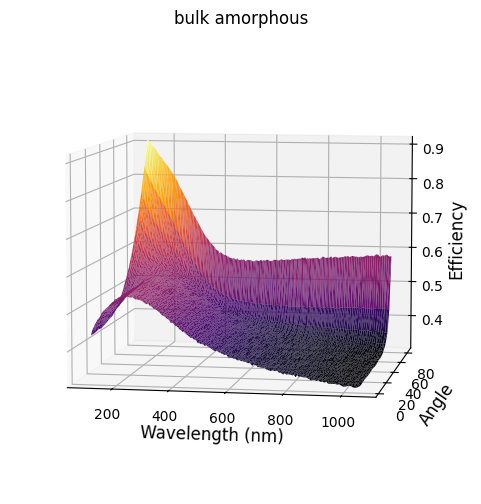

In [9]:
# %matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
cmap = plt.cm.get_cmap('inferno')

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection='3d')

ax.plot_trisurf(dfA.fPhotonWln, dfA.fAngle, dfA.ref, cmap=cmap, linewidth=0.2)

ax.set_title(dfA["dfName"].values[0])
ax.set_xlabel('Wavelength (nm)', fontsize=12)
ax.set_ylabel('Angle', fontsize=12)
ax.set_zlabel('Efficiency', fontsize=12)

# Enable interactive rotation
ax.view_init(elev=7, azim=-80)

plt.show()


In [10]:
# to find what you want
closestAngle = lambda df, angle: df["fAngle"].unique()[np.abs(df["fAngle"].unique() - angle).argmin()]
closestWlen = lambda df, wlen: df["fPhotonWln"].unique()[np.abs(df["fPhotonWln"].unique() - wlen).argmin()]

getDfforAngle = lambda df, angle: df[df["fAngle"] == closestAngle(df, angle)]
getDfforWlen = lambda df, wlen: df[df["fPhotonWln"] == closestWlen(df, wlen)]

removeDuplicates = lambda df, name = "fPhotonWln": df.loc[~df[name].duplicated(keep=False), :]

0       0.52642
1       0.52388
2       0.52661
3       0.52397
4       0.52724
         ...   
3397    0.25565
3398    0.29051
3399    0.34569
3400    0.44714
3401    0.63634
Name: ref, Length: 3402, dtype: float64
0.75593
0.26358886190536834


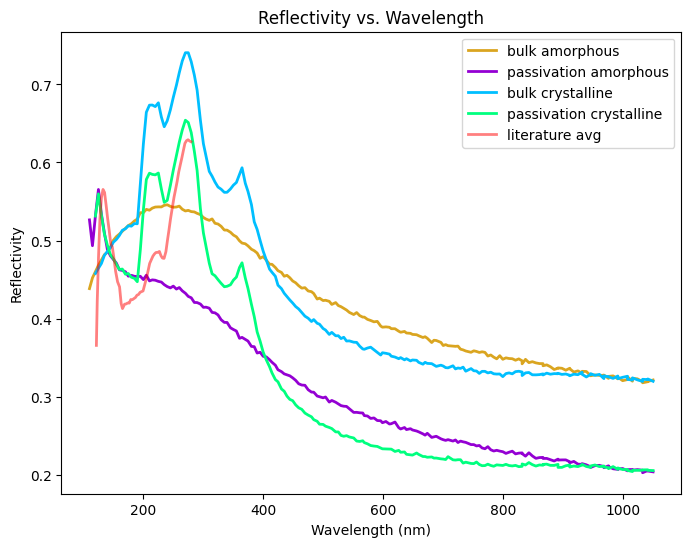

In [11]:
angleWanted = 0
# test = getDfforAngle(dfA, angleWanted)

# test.plot(x = "fPhotonWln", y = "ref", marker = ".", linestyle = "None")

fig, ax = plt.subplots(1, 1, figsize = (8, 6))

for df in dflist:
  df_plot = getDfforAngle(df, angleWanted)
  dfName = df_plot.dfName.unique()[0]
  
  ax.plot(df_plot.fPhotonWln, df_plot.ref, linewidth = 2, label = dfName)


dfScale = getDfforAngle(dfB, angleWanted)
dfScale = removeDuplicates(dfScale)

scaleLit = max(dfScale.ref)/max(vuvR_y[0:10])
print(dfB.ref)
print(max(dfB.ref))
print(max(vuvR_y[0:10]))
# scaleLit = 1


# ax.plot(rvuv[:, 0], rvuv[:, 1]/100, color = "r", linewidth = 2, label = "literature 1")
# ax.plot(rvuv[:, 2], rvuv[:, 3]/100, color = "r", linewidth = 2, label = "literature 1")
ax.plot(vuvR_x, vuvR_y*scaleLit, color = "r", linewidth = 2, alpha = 0.5, label = "literature avg")

# ax.plot(pdeX, pdeY, color = "k", linewidth = 4, label = "Hamamatsu S13360-3050CS")

ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectivity")
ax.set_title("Reflectivity vs. Wavelength")
ax.legend()


In [12]:
# dfFinal = dfD.copy()
dfGood = dfD # passivation on crystalline surface
angleWanted = 0
dfFinal = getDfforAngle(dfGood, angleWanted)
removeDuplicates = lambda df: df.loc[~df['fPhotonWln'].duplicated(keep=False), :]
dfFinal = removeDuplicates(dfFinal)
# print(dfFinal)

r_f = interpolate.interp1d(dfFinal["fPhotonWln"], dfFinal["ref"], kind='cubic', fill_value="extrapolate")
# xvalues for r_f are dfFinal["fPhotonWln"]

pde_f = interpolate.interp1d(pdeX, pdeY, kind='cubic', fill_value="extrapolate")
# x values are pdeX

vuvR_f = interpolate.interp1d(rvuv[:, 0], rvuv[:, 1]/100, kind='cubic', fill_value="extrapolate")
# x values are vuvR_x

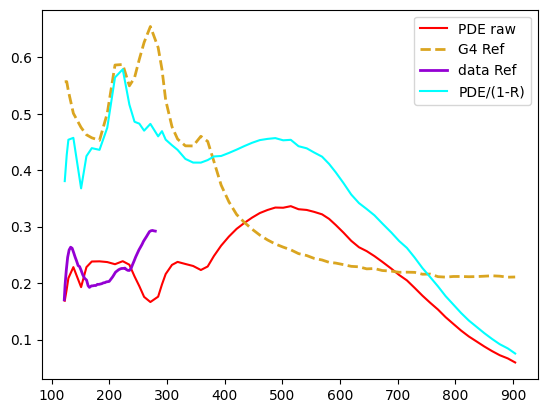

In [26]:
## Only getting PDE' correct (Ref will be wrong)

plt.plot(pdeX, pdeY, color = "red", label = "PDE raw")
plt.plot(pdeX, r_f(pdeX), color = ms.air.col, linewidth = 2, linestyle = "--", label = "G4 Ref")

plt.plot(vuvR_x, vuvR_y, color = ms.lxe.col, linewidth = 2, linestyle = "-", label = "data Ref")

plt.plot(pdeX, pdeY/(1 - r_f(pdeX)), color = "cyan", label = "PDE/(1-R)")

plt.legend()

In [47]:
D = 0.1
# fixed numbers

# different x ranges
wlGap = 1
x_litR = np.arange(min(vuvR_x), max(vuvR_x), wlGap)
xplot_pde = np.arange(min(pdeX), max(pdeX), wlGap)

## rRatios
rRatio = vuvR_f(x_litR)/r_f(x_litR) # only known over literature range
# rRatio_f = lambda x: vuvR_f(x)/r_f(x)

Apartial = 1 - D - rRatio
A_flatEnd = np.append(Apartial, [Apartial[-1]]*(len(xplot_pde) - len(Apartial))) #extend last value
A_flat_fc = interpolate.interp1d(xplot_pde, A_flatEnd, kind='cubic', fill_value="extrapolate")

# now calculate PDE' with the 'normal' A values
# def calc_A_simple(wl, D):
#   return 1 - D - rRatio_f(wl)

def calc_pdeP(pde, A, R, D):
  return pde/(1 - A - D)/(1-R)

def calc_unityA(pde, R, D):
  return 1 - D - pde/(1-R)


pdeP_simplest_min = pde_f(xplot_pde) / (1 - r_f(xplot_pde)) / (1 - A_flat_fc(xplot_pde) - D)

A_massaged = []
pdeP_massaged = []
for wl in xplot_pde:
  
  A = A_flat_fc(wl) # calculated with VUV data extended with last value
  pdeTrue = pde_f(wl) # from manufacturer
  R_g4 = r_f(wl)      # from my study
  
  pdeP = calc_pdeP(pdeTrue, A, R_g4, D) # math with 'simple' A
  
  if pdeP > 1.0:
    A = calc_unityA(pdeTrue, R_g4, D)
    pdeP = calc_pdeP(pdeTrue, A, R_g4, D) # this should give 1.0
  
  A_massaged.append(A)
  pdeP_massaged.append(pdeP)


  

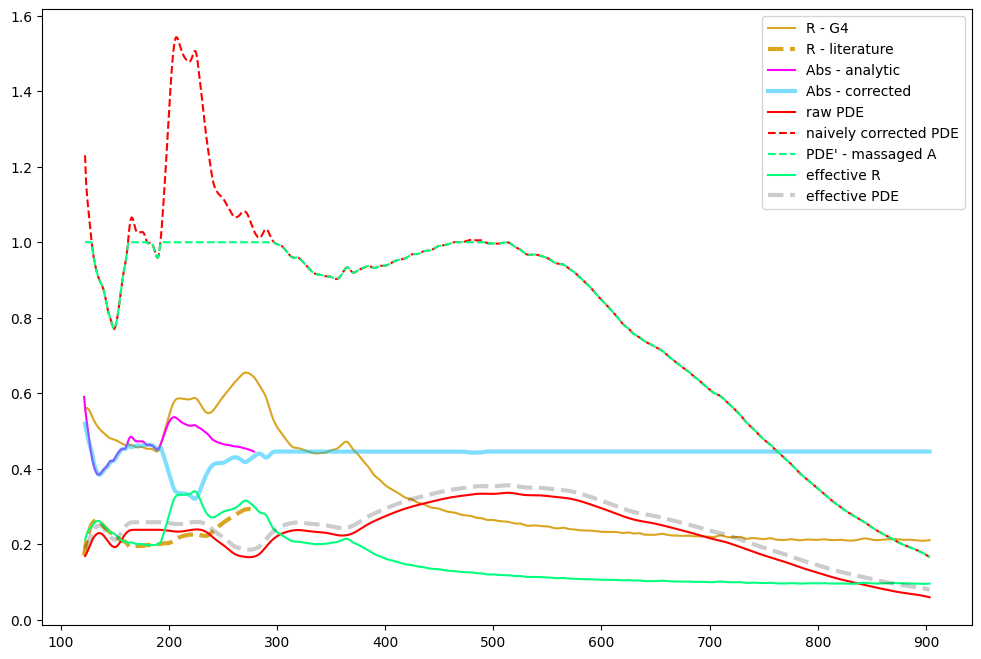

In [63]:
A_massaged = np.array(A_massaged)
plt.figure(figsize = (12, 8))

plt.plot(xplot_pde, r_f(xplot_pde), color = ms.air.col, label = "R - G4")
plt.plot(x_litR, vuvR_f(x_litR), color = ms.air.col, linewidth = 3, linestyle = "--", label = "R - literature")

plt.plot(x_litR, Apartial, color = ms.lxe2.col, label = "Abs - analytic")

plt.plot(xplot_pde, A_massaged, color = ms.cf4.col, linewidth = 3, alpha = 0.5, label = "Abs - corrected")

plt.plot(xplot_pde, pde_f(xplot_pde), color = ms.red.col, label = "raw PDE")
plt.plot(xplot_pde, pdeP_simplest_min, color = ms.red.col, linestyle = "--", label = "naively corrected PDE")
plt.plot(xplot_pde, pdeP_massaged, color = ms.green.col, linestyle = "--", label = "PDE' - massaged A")

plt.plot(xplot_pde, r_f(xplot_pde) * (1 - D - A_massaged), color = ms.green.col, label = "effective R")

plt.plot(xplot_pde, 0.02 + pdeP_massaged * (1 - A_massaged - D) * (1 - r_f(xplot_pde)), color = "k", alpha = 0.2, linewidth = 3, linestyle = "--", label = "effective PDE")

plt.legend()

[0.59051807 0.51260642 0.44965435 0.407251   0.38647937 0.38665265
 0.39779762 0.40663286 0.41963032 0.42171017 0.4358419  0.4479939
 0.45259204 0.45836288 0.48196283 0.4813342  0.47287695 0.47226364
 0.47243129 0.464883   0.4633368  0.46103178 0.45306757 0.45420097
 0.47465418 0.49929878 0.52075895 0.5336245  0.5364189  0.53062821
 0.52349958 0.51873267 0.51510148 0.51382589 0.51547043 0.51072604
 0.50613145 0.4993225  0.49265173 0.48305988 0.47502092 0.47056944
 0.46765957 0.4649045  0.46337495 0.46213131 0.4597068  0.45895766
 0.45755393 0.45489132 0.45309257 0.45002852 0.44710655]
x

0.4718870899746524 0.3864793657884449
0.5135206342115551
0.4281129100253476


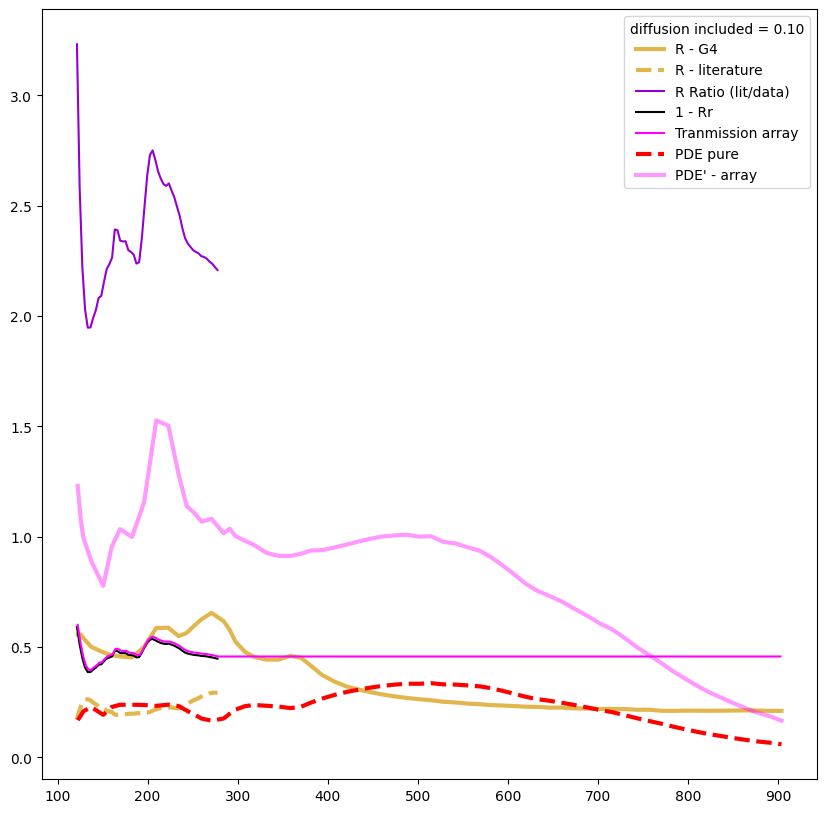

In [25]:
#with D excluded (done 'first')

# pde_f = interpolate.interp1d(pdeX, pdeY, kind='cubic', fill_value="extrapolate")

x_litR = np.arange(min(vuvR_x), max(vuvR_x), 3)
xplot_pde = np.arange(min(pdeX), max(pdeX), 3)
D = 0.1

# over R range
r = r_f(x_litR)
rp = vuvR_f(x_litR)

rRatio = rp/r
Atest_mean = 1 - D - np.mean(rRatio)
Atest_max = 1 - D - max(rRatio)
Atest_array = 1 - D - rRatio

print(Atest_array)
A_full = np.append(Atest_array, [Atest_array[-1]]*(len(xplot_pde) - len(Atest_array)))
a_func = interpolate.interp1d(xplot_pde, A_full, kind='cubic', fill_value="extrapolate")

print("x\n")

print(Atest_mean, Atest_max)
print(max(rRatio))
print(np.mean(rRatio))

pdeP = pdeY / (1 - r_f(pdeX)) / (1 - Atest_max - D)
# pdeP_max = pdeY / (1 - r_f(pdeX)) / (1 - Atest_mean - D)
pde_full = pdeY / (1 - r_f(pdeX)) / (1 - a_func(pdeX) - D)

fig = plt.figure(figsize = (10, 10))
## R values
plt.plot(pdeX, r_f(pdeX), color = ms.air.col, linewidth = 3, alpha = 0.8, label = "R - G4")
plt.plot(x_litR, vuvR_f(x_litR), color = ms.air.col, linestyle = "--", linewidth = 3, alpha = 0.8, label = "R - literature")
plt.plot(x_litR, r_f(x_litR)/vuvR_f(x_litR), color = ms.lxe.col, linestyle = "-", label = "R Ratio (lit/data)")

## Abs values
# plt.plot(x_litR, [Atest_max] * len(x_litR), color = ms.green.col, linestyle = "--", label = "Tranmission max")
# plt.plot(x_litR, [Atest_mean] * len(x_litR), color = ms.cf4.col, linestyle = "--", label = "Tranmission mean")
plt.plot(x_litR, Atest_array, color = 'black', linestyle = "-", label = "1 - Rr")

plt.plot(xplot_pde, A_full+0.01, color = ms.lxe2.col, linestyle = "-", label = "Tranmission array")

## PDE
plt.plot(pdeX, pdeY, color = "red", linestyle = "--", linewidth = 3, label = "PDE pure")


# plt.plot(pdeX, pdeP, color = ms.cf4.col, label = "PDE' - max")

# plt.plot(pdeX, pdeP_max, color = ms.green.col, label = "PDE' - mean")

plt.plot(pdeX, pde_full, color = ms.lxe2.col, linewidth = 3, alpha = 0.4, label = "PDE' - array")

plt.legend(title = f"diffusion included = {D:0.2f}")